# NumCompute-Stream demo

Generates a synthetic classification dataset, streams it through a Pipeline (streaming scaler + streaming decision tree) in chunks, trains incrementally with .partial_fit(), and visualises accuracy over time with visualise.py.

Steps:
1. Generate stream_dataset.csv.
2. Load it in chunks via numcompute.io.load_csv_chunks.
3. Build a streaming Pipeline (StreamingStandardScaler + DecisionTreeClassifier).
4. Train incrementally, chunk by chunk, with StreamTrainer.
5. Visualise accuracy over time and predictions vs ground truth.
6. Compare two buffer_size settings.
7. Inspect the per-chunk logs.

In [20]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # numcompute_stream is not pip-installed

%matplotlib inline
import numpy as np

from numcompute.io import load_csv_chunks
from numcompute_stream.preprocessing import StreamingStandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import plot_metric_over_time, compare_models, plot_predictions_vs_ground_truth

## 1. Generate the dataset

In [21]:
def create_stream_dataset(filename="stream_dataset.csv", num_rows=2000, noise=0.08, seed=7):
    rng = np.random.default_rng(seed)

    feature_1 = rng.normal(50, 15, size=num_rows)  # mean 50, std 15
    feature_2 = rng.uniform(0, 1000, size=num_rows)  # between 0 and 1000
    feature_3 = rng.choice([0, 1, 2], size=num_rows).astype(np.float64)  # categorical, 0/1/2

    score = feature_1 + 0.05 * feature_2 + 10.0 * feature_3
    true_label = (score > np.median(score)).astype(np.int64)

    flip = rng.random(num_rows) < noise
    label = np.where(flip, 1 - true_label, true_label)

    header = "feature_1,feature_2,feature_3,label"
    data = np.column_stack([feature_1, feature_2, feature_3, label])
    np.savetxt(filename, data, delimiter=",", header=header, comments="", fmt="%.4f,%.4f,%.0f,%d")

    print(f"Data successfully generated and saved to {filename}")


create_stream_dataset("stream_dataset.csv", num_rows=2000)

Data successfully generated and saved to stream_dataset.csv


## 2. Load the dataset in chunks

load_csv_chunks reads stream_dataset.csv off disk 100 rows at a time, simulating data arriving as a stream rather than all at once.

In [22]:
DATA_PATH = "stream_dataset.csv"
CHUNK_SIZE = 100

all_chunks = []
for chunk in load_csv_chunks(DATA_PATH, chunk_size=CHUNK_SIZE, skip_header=1):
    X_chunk = chunk[:, :-1]
    y_chunk = chunk[:, -1].astype(np.int64)
    all_chunks.append((X_chunk, y_chunk))

print(f"Loaded {len(all_chunks)} chunks of up to {CHUNK_SIZE} rows each.")
print("First chunk's features:\n", all_chunks[0][0][:3])

Loaded 20 chunks of up to 100 rows each.
First chunk's features:
 [[ 50.0185 402.3035   0.    ]
 [ 54.4812 789.7991   0.    ]
 [ 45.8879  39.0024   0.    ]]


## 3. Build the streaming pipeline

Pipeline chains a StreamingStandardScaler into a DecisionTreeClassifier, each updated chunk by chunk.

In [23]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("scale", StreamingStandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=4, buffer_size=buffer_size)),
    ])


def make_trainer(pipeline, chunks, buffer_size, chunk_size):
    n_priming_chunks = -(-buffer_size // chunk_size)  # ceil division
    priming_chunks = chunks[:n_priming_chunks]
    remaining_chunks = chunks[n_priming_chunks:]

    for X_chunk, y_chunk in priming_chunks:
        pipeline.partial_fit(X_chunk, y_chunk)

    trainer = StreamTrainer(pipeline)
    for X_chunk, y_chunk in remaining_chunks:
        trainer.fit_chunk(X_chunk, y_chunk)

    return trainer, remaining_chunks

## 4. Train incrementally with partial_fit

StreamTrainer.fit_chunk calls pipeline.partial_fit then scores that same chunk, logging chunk_accuracy, cumulative_accuracy, and an estimated memory_bytes to trainer.history.

In [24]:
primary_pipeline = make_pipeline(buffer_size=200)
trainer, primary_remaining = make_trainer(
    primary_pipeline, all_chunks, buffer_size=200, chunk_size=CHUNK_SIZE
)

print(f"Logged {len(trainer.history)} chunks.")
print("First log entry:", trainer.history[0])
print("Last log entry:", trainer.history[-1])

Logged 18 chunks.
First log entry: {'chunk_accuracy': 0.79, 'cumulative_accuracy': 0.79, 'memory_bytes': 4137}
Last log entry: {'chunk_accuracy': 0.87, 'cumulative_accuracy': 0.84, 'memory_bytes': 933}


## 5. Visualise metrics over time

Cumulative accuracy across every scored chunk, and predictions vs ground truth on the most recent chunk.

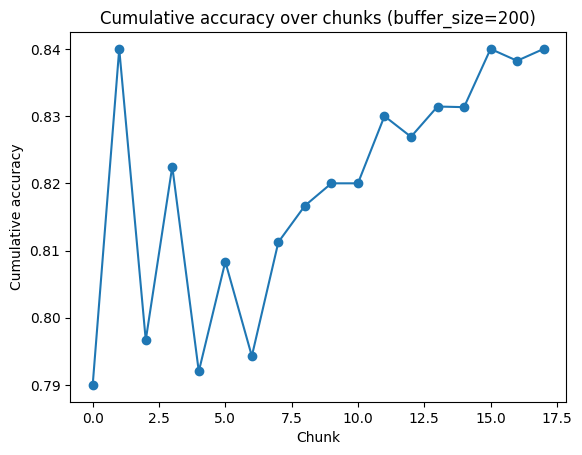

In [25]:
cumulative_accuracy = np.array([entry["cumulative_accuracy"] for entry in trainer.history])

plot_metric_over_time(
    cumulative_accuracy,
    title="Cumulative accuracy over chunks (buffer_size=200)",
    ylabel="Cumulative accuracy",
);

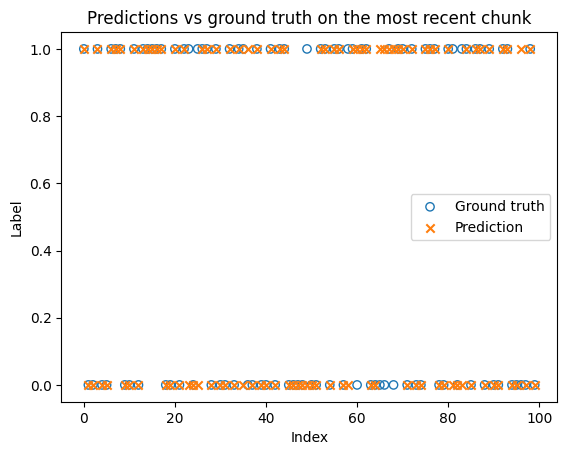

In [26]:
final_X, final_y = primary_remaining[-1]
final_predictions = primary_pipeline.predict(final_X)

plot_predictions_vs_ground_truth(
    final_y, final_predictions,
    title="Predictions vs ground truth on the most recent chunk",
);

## 6. Compare buffer_size settings

A small buffer (buffer_size=100, retrains every chunk) vs a large one (buffer_size=500, retrains every 5 chunks) on the same stream.

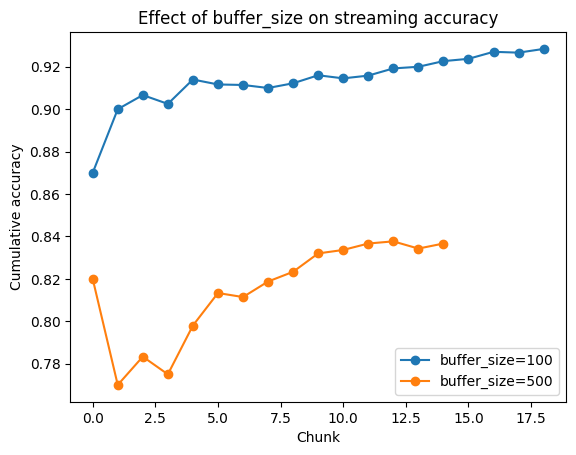

In [27]:
buffer_sizes = (100, 500)
trainers = {}
for buffer_size in buffer_sizes:
    trainers[buffer_size], _ = make_trainer(make_pipeline(buffer_size), all_chunks, buffer_size, CHUNK_SIZE)

small_cumulative = np.array([entry["cumulative_accuracy"] for entry in trainers[100].history])
large_cumulative = np.array([entry["cumulative_accuracy"] for entry in trainers[500].history])

compare_models(
    small_cumulative, large_cumulative,
    labels=("buffer_size=100", "buffer_size=500"),
    title="Effect of buffer_size on streaming accuracy",
    ylabel="Cumulative accuracy",
);

## 7. Inspect the logs

Every fit_chunk call appends one entry to trainer.history. Here are the first and last few chunks of the primary run (buffer_size=200).

In [28]:
print(f"{'chunk':>6} {'chunk_accuracy':>16} {'cumulative_accuracy':>20} {'memory_bytes':>14}")
for chunk_index, entry in enumerate(trainer.history):
    if chunk_index < 3 or chunk_index >= len(trainer.history) - 3:
        print(
            f"{chunk_index:>6} "
            f"{entry['chunk_accuracy']:>16.4f} "
            f"{entry['cumulative_accuracy']:>20.4f} "
            f"{entry['memory_bytes']:>14}"
        )

 chunk   chunk_accuracy  cumulative_accuracy   memory_bytes
     0           0.7900               0.7900           4137
     1           0.8900               0.8400            933
     2           0.7100               0.7967           4137
    15           0.9700               0.8400            933
    16           0.8100               0.8382           4137
    17           0.8700               0.8400            933
